# Analysis of the activities per visit or per table

The main questions are:
1. What is the average number of actvities per unit of time?
2. On average how many activities require a visit to the base before the activity or a visit to base after an activity?
3. Percentage of activities without guests at table
4. What the best dirichlet distribution parameter for the gap time distribution between activities of a visit?



In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import ast
import numpy as np
import scipy.stats as stats
import openturns as ot
from math import ceil
import datetime
from collections import defaultdict

In [2]:
filename = Path('./data/processed/20210818_evening_staff_activities.csv')
df_staff_activities = pd.read_csv(filename, parse_dates=['start_time', 'end_time'])

dtypes = {'group_size': 'int', 'fully_captured': 'bool', 'visit_time': 'float'}
filename = Path('./data/processed/20210818_evening_guest_demand.csv')
df_guest_demand = pd.read_csv(filename, dtype=dtypes, parse_dates=['start_time', 'end_time'])

measurement_pause = (datetime.datetime(2021, 8, 18, 18, 59), datetime.datetime(2021, 8, 18, 20, 4))

In [3]:
activities_per_table_per_visit_per_measurement_period = []
import datetime
activities_processed = None

for _, row in df_guest_demand.iterrows():
    table_id = row['table_id']
    start_time = row['start_time']
    end_time = row['end_time']
    
    if pd.isnull(end_time):
        end_time = datetime.datetime.now()
           
    df_activities = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] >= start_time) & (df_staff_activities['end_time'] <= end_time)]
    
    try:
        activities_processed = pd.concat([activities_processed, df_activities])
    except:
        activities_processed = df_activities
    
    df_activities_before = df_activities[df_activities['start_time'] <= measurement_pause[0]]
    df_activities_after = df_activities[df_activities['start_time'] > measurement_pause[0]]
    
    if len(df_activities) != len(df_activities_before) + len(df_activities_after):
        raise Exception('Missing')
    
    if len(df_activities) == 0:
        print(f'{table_id} ({start_time} - {end_time}) has no activities')
        continue
    
    if len(df_activities_before) > 0:    
        activities_per_table_per_visit_per_measurement_period.append(df_activities_before)
    if len(df_activities_after) > 0:    
        activities_per_table_per_visit_per_measurement_period.append(df_activities_after)

14 (2021-08-18 17:12:11 - 2021-08-18 17:37:41) has no activities
20 (2021-08-18 18:28:32 - 2021-08-18 19:20:30) has no activities
33 (2021-08-18 18:11:12 - 2021-08-18 20:13:42) has no activities
23 (2021-08-18 17:33:44 - 2021-11-30 13:53:51.425428) has no activities
B3 (2021-08-18 20:10:07 - 2021-11-30 13:53:51.457772) has no activities
33 (2021-08-18 20:54:24 - 2021-11-30 13:53:51.459745) has no activities


## Number of activities per unit of time

In [4]:
activities_per_hour = []
gaps_per_set = []

for activity_set in activities_per_table_per_visit_per_measurement_period:
        min_time = min(np.array(activity_set['start_time']))
        max_time = max(np.array(activity_set['end_time']))
        activity_count = len(activity_set)
        if activity_count <= 1: 
            continue
        meas_period = ((max_time - min_time)/np.timedelta64(1, 'h'))
        if meas_period > 0.5: 
            activities_per_hour.append(activity_count/meas_period)
        
        gaps_of_set = (np.array(activity_set['start_time'][1:activity_count]) - np.array(activity_set['start_time'][0:activity_count-1]))/np.timedelta64(1, 's') 
        gaps_per_set.append(gaps_of_set)
        
        #if np.any(gaps_of_set > 1800):
        #    print(activity_set)
        #    print('')

Average number of activities per hour 8.84 [#activities/hour]


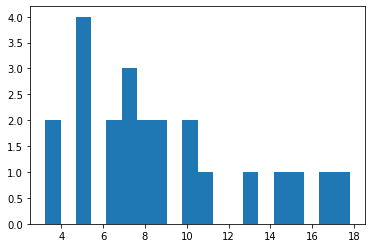

In [5]:
hist = plt.hist(activities_per_hour, bins=20)
print(f'Average number of activities per hour {np.mean(activities_per_hour):.2f} [#activities/hour]')

## Activities per table

In [6]:
activities_per_table = defaultdict(list)
last_activity_processed = {}

for _, row in df_guest_demand.iterrows():
    table_id = row['table_id']
    start_time = row['start_time']
    end_time = row['end_time']

    if table_id not in last_activity_processed:
        df_actvities_gap = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] < start_time)]
    else:
        df_actvities_gap = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] < start_time) & (df_staff_activities['start_time'] > last_activity_processed[table_id])]

    if len(df_actvities_gap) > 0:
        activities_per_table[table_id].append((False,df_actvities_gap))
            
    if pd.isnull(end_time):
        df_activities = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] >= start_time)]
    else:   
        df_activities = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] >= start_time) & (df_staff_activities['end_time'] <= end_time)]
        
    df_activities_before = df_activities[df_activities['start_time'] <= measurement_pause[0]]
    df_activities_after = df_activities[df_activities['start_time'] > measurement_pause[0]]
    
    if len(df_activities) != len(df_activities_before) + len(df_activities_after):
        raise Exception('Missing')
    
    if len(df_activities) == 0:
        print(f'{table_id} ({start_time} - {end_time}) has no activities')
        continue
    
    if len(df_activities_before) > 0:    
        activities_per_table[table_id].append((True, df_activities_before))
        if len(df_activities_after) == 0:
            last_activity_processed[table_id] = df_activities_before['start_time'].iloc[-1]
            
    if len(df_activities_after) > 0:    
        activities_per_table[table_id].append((True, df_activities_after))
        last_activity_processed[table_id] = df_activities_after['start_time'].iloc[-1]
        
for table_id, end_time in last_activity_processed.items():
    df_actvities_gap = df_staff_activities[(df_staff_activities['table_id'] == table_id) & (df_staff_activities['start_time'] > end_time)]
    if len(df_actvities_gap) > 0:
        activities_per_table[table_id].append((False, df_actvities_gap))
    
    

14 (2021-08-18 17:12:11 - 2021-08-18 17:37:41) has no activities
20 (2021-08-18 18:28:32 - 2021-08-18 19:20:30) has no activities
33 (2021-08-18 18:11:12 - 2021-08-18 20:13:42) has no activities
23 (2021-08-18 17:33:44 - NaT) has no activities
B3 (2021-08-18 20:10:07 - NaT) has no activities
33 (2021-08-18 20:54:24 - NaT) has no activities


## On average how many activities require a visit to the base before the activity or a visit to base after an activity?

In [7]:
df_staff_activities['activity_type'] = df_staff_activities['activity_type'].str.upper()

activity_types = {
    'base_first': ('S', 'CUTLERY', 'B', 'W'),
    'base_after': ('R', 'C'),
    'no_base': ('F', 'O', 'P')
}

activity_type_count = {key:0 for key in activity_types}

check = None

for key, activity_types_of_base_type in activity_types.items():
    for activity_type in activity_types_of_base_type:
        contains_activity = df_staff_activities['activity_type'].str.contains(activity_type)
        activity_type_count[key] += len(df_staff_activities[contains_activity == True])
        if check is None:
            check = contains_activity
        else:
            check = check | contains_activity

print(activity_type_count)
count_sum = sum(activity_type_count.values())
print({key:value/count_sum for key, value in activity_type_count.items()})
df_staff_activities[check == False]

{'base_first': 191, 'base_after': 137, 'no_base': 141}
{'base_first': 0.4072494669509595, 'base_after': 0.2921108742004264, 'no_base': 0.3006396588486141}


,table_id,staff_id,start_time,end_time,activity_type
